Solution found!
Task 1: Start = 0, End = 10, Mode = 2
Task 2: Start = 10, End = 20, Mode = 2
Task 3: Start = 10, End = 18, Mode = 1
Task 4: Start = 20, End = 32, Mode = 1
Task 5: Start = 30, End = 36, Mode = 2
Task 6: Start = 32, End = 40, Mode = 1
Task 7: Start = 36, End = 42, Mode = 1
Task 8: Start = 40, End = 48, Mode = 1
Task 9: Start = 42, End = 48, Mode = 1
Task 10: Start = 42, End = 48, Mode = 2
Task 11: Start = 42, End = 48, Mode = 2
Task 12: Start = 48, End = 52, Mode = 2
Task 13: Start = 0, End = 10, Mode = 1
Task 14: Start = 10, End = 18, Mode = 2
Task 15: Start = 18, End = 22, Mode = 2
Task 16: Start = 0, End = 8, Mode = 2
Task 17: Start = 8, End = 14, Mode = 1
Task 18: Start = 14, End = 22, Mode = 1
Task 19: Start = 22, End = 26, Mode = 2
Task 20: Start = 26, End = 36, Mode = 1
Task 21: Start = 36, End = 50, Mode = 1
Task 22: Start = 37, End = 53, Mode = 1
Task 23: Start = 0, End = 10, Mode = 2
Task 24: Start = 10, End = 24, Mode = 1
Task 25: Start = 24, End = 40, Mode = 1

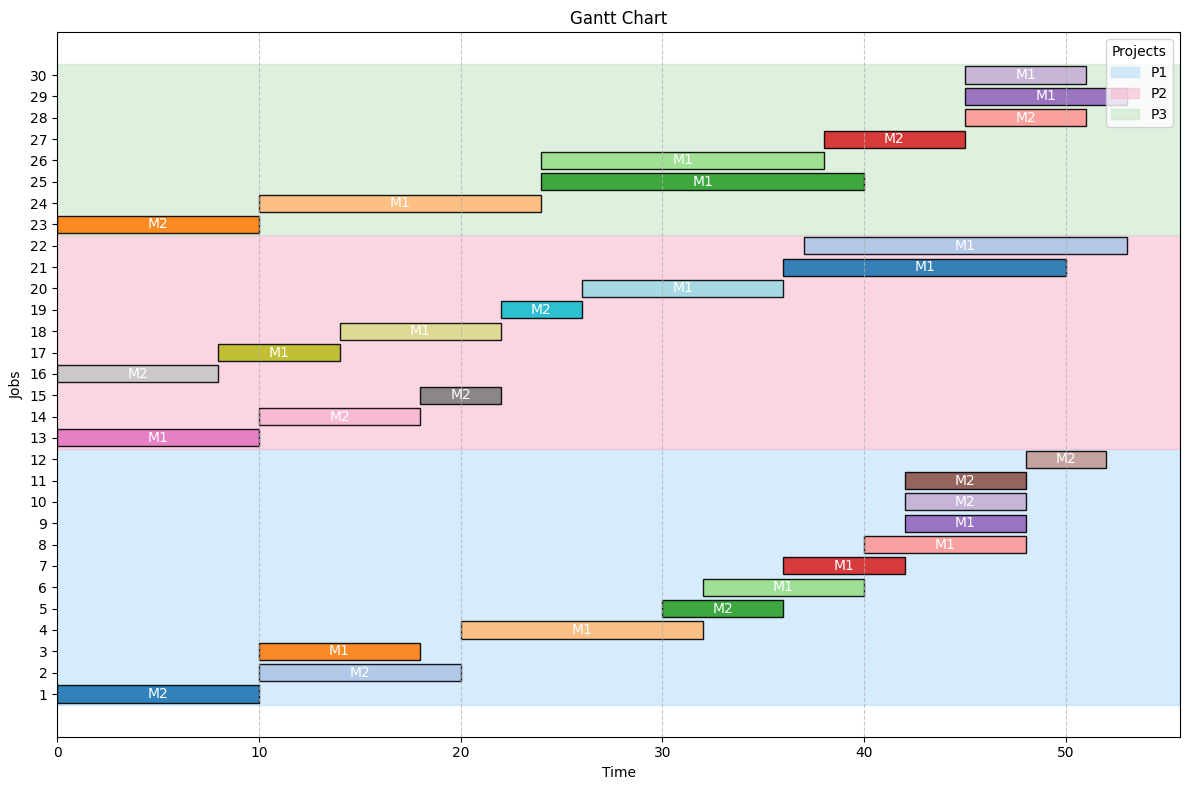

In [ ]:
from ortools.sat.python import cp_model
from complex_gantt import complex_gantt
from complex_parser import parse_data

# Load data from the dataset
try:
    data = parse_data("complex_dataset.txt")
except FileNotFoundError:
    raise Exception("The file complex_dataset.txt was not found. Please check the path.")
except Exception as e:
    raise Exception(f"Error loading data: {e}")

# Validate data
required_keys = ["projects", "tasks", "precedence", "time_windows", "resources", "proximity_constraints"]
for key in required_keys:
    if key not in data:
        raise ValueError(f"Invalid input data: missing key '{key}'.")

projects = data["projects"]
tasks = data["tasks"]
precedence = data["precedence"]
time_windows = data["time_windows"]
resources = data["resources"]
proximity_constraints = data["proximity_constraints"]

# Model
model = cp_model.CpModel()

# Validate data consistency
def validate_input_data():
    """Validate the consistency of input data."""
    for task, modes in tasks.items():
        if not modes:
            raise ValueError(f"Task '{task}' has no defined modes.")
    for task, successors in precedence.items():
        if task not in tasks:
            raise ValueError(f"Precedence task '{task}' does not exist in 'tasks'.")
        for succ in successors:
            if succ not in tasks:
                raise ValueError(f"Successor '{succ}' of '{task}' does not exist in 'tasks'.")
    for resource_type in ["renewable", "non-renewable"]:
        if resource_type not in resources:
            raise ValueError(f"Resource type '{resource_type}' is missing in the data.")
validate_input_data()

# Variables
horizon = sum(max(m[1][0] for m in modes) for modes in tasks.values())
start_times = {task: model.NewIntVar(0, horizon, f"start_{task}") for task in tasks}
end_times = {task: model.NewIntVar(0, horizon, f"end_{task}") for task in tasks}
modes = {task: model.NewIntVar(0, len(tasks[task]) - 1, f"mode_{task}") for task in tasks}

# Sort tasks by the number of successors (most critical first)
critical_tasks = sorted(precedence.keys(), key=lambda t: len(precedence[t]), reverse=True)

# Auxiliary functions
def create_mode_variables():
    """Create boolean variables and intervals for task modes."""
    is_modes = {}
    intervals = {}
    for task, task_modes in tasks.items():
        is_modes[task] = []
        intervals[task] = []
        for mode_id, (mode_index, (duration, _)) in enumerate(task_modes):
            is_mode = model.NewBoolVar(f"is_mode_{task}_{mode_id}")
            is_modes[task].append(is_mode)
            # Link modes to variables
            model.Add(modes[task] == mode_id).OnlyEnforceIf(is_mode)
            model.Add(modes[task] != mode_id).OnlyEnforceIf(is_mode.Not())
            # Optional interval
            intervals[task].append(
                model.NewOptionalIntervalVar(
                    start_times[task], duration, end_times[task], is_mode, f"interval_{task}_{mode_id}"
                )
            )
        # Ensure only one mode is selected
        model.Add(sum(is_modes[task]) == 1)
    return is_modes, intervals

def add_precedence_constraints():
    """Add precedence constraints between tasks in critical order."""
    for task in critical_tasks:
        for succ in precedence.get(task, []):
            model.Add(start_times[succ] >= end_times[task])

def add_time_window_constraints():
    """Add time window constraints."""
    for task, (min_time, max_time) in time_windows.items():
        model.Add(start_times[task] >= min_time)
        model.Add(end_times[task] <= max_time)

def add_proximity_constraints():
    """Add proximity constraints between tasks."""
    for t1, t2, max_diff in proximity_constraints:
        model.Add(start_times[t2] - end_times[t1] <= max_diff)
        model.Add(end_times[t1] - start_times[t2] <= max_diff)

def add_resource_constraints():
    """Add constraints for renewable and non-renewable resources."""
    # Renewable resources
    for resource, capacity in resources["renewable"].items():
        for project_name, task_ids in projects.items():
            demands, intervals_list = [], []
            for task in task_ids:
                for mode_id, (_, (_, usage)) in enumerate(tasks[task]):
                    if resource in usage:
                        demands.append(usage[resource])
                        intervals_list.append(intervals[task][mode_id])
            if intervals_list:
                model.AddCumulative(intervals_list, demands, capacity)
    # Non-renewable resources
    for resource, capacity in resources["non-renewable"].items():
        total_usage = []
        for task_ids in projects.values():
            project_usage = [
                usage[resource] * is_modes[task][mode_id]
                for task in task_ids
                for mode_id, (_, (_, usage)) in enumerate(tasks[task])
                if resource in usage
            ]
            total_usage.append(sum(project_usage))
        model.Add(sum(total_usage) <= capacity)

# Auxiliary function to calculate total resource usage
def calculate_total_resource_usage():
    """Calculate total resource usage based on the selected mode."""
    resource_usage = []
    for task in tasks:
        for mode_id, (_, (_, usage)) in enumerate(tasks[task]):
            for resource, amount in usage.items():
                resource_usage.append(amount * is_modes[task][mode_id])
    return sum(resource_usage)

# Create mode variables and intervals
is_modes, intervals = create_mode_variables()

# Add constraints to the model
add_precedence_constraints()
add_time_window_constraints()
add_proximity_constraints()
add_resource_constraints()

# Makespan variable
makespan = model.NewIntVar(0, horizon, "makespan")
for task in end_times.values():
    model.Add(makespan >= task)

# Calculate total resource usage
total_resource_usage = calculate_total_resource_usage()

# Define objective function: Minimize makespan and resource usage
model.Minimize(makespan + total_resource_usage * 0.01)  # 0.01 adjusts priority between makespan and resources

# Solve the model
solver = cp_model.CpSolver()
solver.parameters.max_time_in_seconds = 300
solver.parameters.log_search_progress = True
status = solver.Solve(model)

# Output
if status in (cp_model.OPTIMAL, cp_model.FEASIBLE):
    print("Solution found!")
    schedule = [
        (task, solver.Value(start_times[task]), solver.Value(end_times[task]), solver.Value(modes[task]) + 1)
        for task in tasks
    ]
    for task, start, end, mode in schedule:
        print(f"Task {task}: Start = {start}, End = {end}, Mode = {mode}")
    complex_gantt(projects, schedule)
else:
    print("No feasible solution found. Check the constraints or time limit.")


# Advanced Planning with OR-Tools

## Implemented Features

### 1. Task Multimodality
Each task can be executed in different **modes**, varying in their durations and resource consumption. The solver determines the best mode for each task, aiming to minimize the impact on the schedule and resource usage.

#### **Solver's Mode Selection Logic**
- For each task, boolean variables are created to represent whether a specific mode is selected.
- The solver prioritizes modes with lower resource consumption unless this increases the total project makespan.
- Only one mode can be selected per task, ensuring consistency.

#### **Challenges and Complexity**
Mode selection adds complexity as the solver must balance between longer durations (which increase the makespan) and lower resource consumption (which preserves resource capacities).

---

### 2. Time Windows Constraints
Tasks must start and finish within specific time intervals, known as **time windows**.

#### **Model Logic**
- Each task has a minimum (`min_time`) and maximum (`max_time`) allowed start and finish time.
- The solver adjusts the schedule to ensure no task violates these constraints.

#### **Impact on Planning**
Time windows make the problem more realistic by reflecting deadlines and resource availability periods. They add complexity as the solver must address potential timing conflicts.

---

### 3. Use of Shared Resource Groups (Non-Renewable)
Non-renewable resources, such as budgets, materials, or energy, are shared among all projects, with a total capacity limit.

#### **Model Logic**
- The total usage of each resource is calculated across all tasks in all projects.
- The solver ensures that the total usage does not exceed the defined resource capacity.
- This requires aggregating resource consumption from different projects.

#### **Challenges and Complexity**
Managing non-renewable resources introduces interdependence between tasks and projects. The solver must allocate resources efficiently while adhering to project-specific demands and global capacity limits.

---

### 4. Heuristics and Search Strategies
Tasks are ordered based on the number of successors (most critical first) to optimize the schedule. This order directly influences the addition of precedence constraints.

#### **Critical Task Prioritization**
- Tasks are sorted by the number of successors, prioritizing those with the most dependencies.
- Precedence constraints are added in this order, ensuring that critical tasks are addressed earlier in the scheduling process.

#### **Solver Optimization**
- The solver's search strategy is configured to explore decisions for critical tasks first, improving the overall efficiency of the solution process.

---

### 5. Multi-Project Planning
The model supports simultaneous planning of multiple projects. Each project has a set of tasks, and resources are shared globally across all projects.

#### **Global Resource Management**
- Tasks from different projects compete for shared resources, requiring careful allocation by the solver.
- This reflects real-world scenarios where teams or resources are shared between different initiatives.

#### **Impact**
Multi-project planning adds scalability to the model, enabling it to handle complex, interdependent workflows.

---

### 6. Proximity Constraints
Certain tasks have proximity dependencies, requiring them to be scheduled close to one another within a maximum time difference.

#### **Model Logic**
- For each proximity constraint `(task1, task2, max_diff)`, the solver ensures:
  - `start_time[task2] - end_time[task1] <= max_diff`
  - `end_time[task1] - start_time[task2] <= max_diff`
- This ensures that the temporal relationship between the tasks is maintained.

#### **Challenges and Realism**
Proximity constraints increase the problem's complexity, particularly in scenarios where multiple constraints interact. They are essential for representing tasks that need to be executed in close succession (e.g., dependent steps in a production process).

---

## Model Complexity
This model incorporates several advanced features, significantly increasing its complexity:
- **Task multimodality** requires optimal mode selection for each task.
- **Shared resources** introduce interdependence between tasks and projects.
- **Multi-project planning** expands the problem's scale and scope.
- **Precedence and proximity constraints** ensure realistic scheduling and temporal dependencies.

---

## Solver Optimization
The solver's performance is enhanced through:
1. **Critical Task Prioritization**:
   - Tasks with more successors are processed first.
2. **Search Strategy Configuration**:
   - Fixed branching is used to prioritize critical decision points.
   - The solver is limited to a maximum runtime to ensure timely results:
     ```python
     solver.parameters.search_branching = cp_model.FIXED_SEARCH
     solver.parameters.max_time_in_seconds = 300
     solver.parameters.log_search_progress = True
     ```

---

## Conclusion
This model implements a sophisticated scheduling system that adheres to multiple constraints and optimizations. The integration of task multimodality, multi-project planning, and heuristics makes the model robust and scalable for real-world applications.

**Expected Results**:
- An optimized schedule that respects all constraints.
- Efficient resource allocation across tasks and projects.
- Visual validation of the schedule using Gantt charts (`complex_gantt`).
